# Trial shapes: CCA and reduced-rank regression between vigor and NM photometry

Split from `7_nm_syllable_effects.ipynb`. Each trial is one photometry vector and one vigor vector (whole time courses), so behaviour and the NM signal are related without discretising either side. Run `python neuromodulators/run_nm_syllable_effects.py 14 shapes` first; it caches `shapes_<RUN>.pkl`.

In [1]:
import sys, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'Functions' / 'nm_syllables.py').exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
from Functions import nm_syllables as ns
for msg in ['Mean of empty slice', 'Degrees of freedom', 'invalid value encountered', 'divide by zero']:
    warnings.filterwarnings('ignore', message=msg)

CACHE = ns.DATA / 'syllables_photometry'
NM_ORDER = ['DR-5HT', 'VTA-DA', 'SNc-DA', 'LC-NE', 'NBM-ACh']

## Method

In notebook 7 each time sample was fitted on its own. Here each trial is one vector per side, so that whole time courses are related without discretising either side into modes:
- **photometry**: stimulus window −0.5 to +0.5 s and feedback window −0.5 to +1 s, unmasked, binned to 10 Hz (25 values);
- **vigor**: the same windows and bins for log(1 + ·) of paw speed, wheel speed, whisker ME and lick rate (100 values).

Unmasked means that a short-RT trial has the same samples in both windows and the pre-stimulus window can reach into the previous ITI. That's fine for shapes, but it differs from notebook 7. Nothing is regressed out, so the first dimensions are expected to carry the task timing (RT, outcome), and the later ones whatever remains. Rewarded and error trials are pooled. Only trials with every sample present are used (fibers with ≥ 100 such trials).

- **CCA** (`ns.cca_cv`): PCA to 10 dims on each side (the regularisation), then CCA. The canonical correlations are scored on held-out folds (5-fold). Null = the same with trials shuffled between the two sides, 20 times. That null removes everything, including the shared task structure, so it is lenient: we will need a better one (e.g. shuffles within outcome × RT bins).
- **Reduced-rank regression** (`ns.rrr_cv`): photometry ~ vigor (PCA to 10 dims), with the prediction restricted to rank 1–5. Score = held-out R² of the whole photometry trace across trials (the mean trace is removed). The axes are the photometry patterns that vigor predicts, ordered by how much they explain.

Structure coefficients (correlation of each original value with a canonical variate) are shown instead of raw weights, which are unstable with correlated inputs. Signs are arbitrary per session, so they are aligned to the NM's mean before averaging; dimension order can still swap between sessions with close correlations.

In [2]:
SH = pd.read_pickle(CACHE / f'shapes_{ns.RUN}.pkl')
YLAB, XLAB = SH.attrs['y_labels'], SH.attrs['x_labels']
null95 = lambda a: np.percentile(a, 95, axis=0)
SH['cca dims > null'] = SH.apply(lambda r: int(np.argmin(np.r_[r['cca_r'] > null95(r['cca_r_null']), False])), axis=1)

def by_mouse(g, col, f=lambda x: x):
    return np.stack([np.mean([f(v) for v in gm[col]], 0) for _, gm in g.groupby('subject')])

rows = []
for nm in NM_ORDER:
    g = SH[SH['target_NM'] == nm]
    r, rn, r2 = by_mouse(g, 'cca_r'), by_mouse(g, 'cca_r_null', null95), by_mouse(g, 'rrr_r2') * 100
    rows.append({'NM': nm, 'mice': len(r), 'fibers': len(g), 'median trials': int(g['n_trials'].median()),
                 'CCA r, dims 1–5': ' '.join(f'{v:.2f}' for v in r.mean(0)[:5]),
                 'null 95%': ' '.join(f'{v:.2f}' for v in rn.mean(0)[:5]),
                 'dims > null (median)': g['cca dims > null'].median(),
                 'RRR R² %, rank 1–5': ' '.join(f'{v:.1f}' for v in r2.mean(0))})
pd.DataFrame(rows).set_index('NM')

,mice,fibers,median trials,"CCA r, dims 1–5",null 95%,dims > null (median),"RRR R² %, rank 1–5"
NM,,,,,,,
DR-5HT,9,140,746,0.46 0.35 0.30 0.23 0.16,0.09 0.07 0.07 0.07 0.07,6.0,4.4 6.7 7.8 8.4 8.6
VTA-DA,7,140,745,0.50 0.32 0.29 0.21 0.16,0.09 0.09 0.08 0.08 0.08,7.0,7.7 8.9 9.4 9.5 9.6
SNc-DA,6,65,681,0.54 0.41 0.35 0.26 0.22,0.09 0.08 0.08 0.07 0.07,7.0,6.8 8.7 9.7 10.2 10.4
LC-NE,8,96,586,0.47 0.39 0.32 0.24 0.21,0.08 0.08 0.07 0.08 0.08,8.0,4.9 7.1 8.3 8.8 9.1
NBM-ACh,7,75,853,0.43 0.32 0.28 0.20 0.16,0.08 0.07 0.06 0.06 0.06,6.0,3.3 5.4 6.7 7.2 7.4


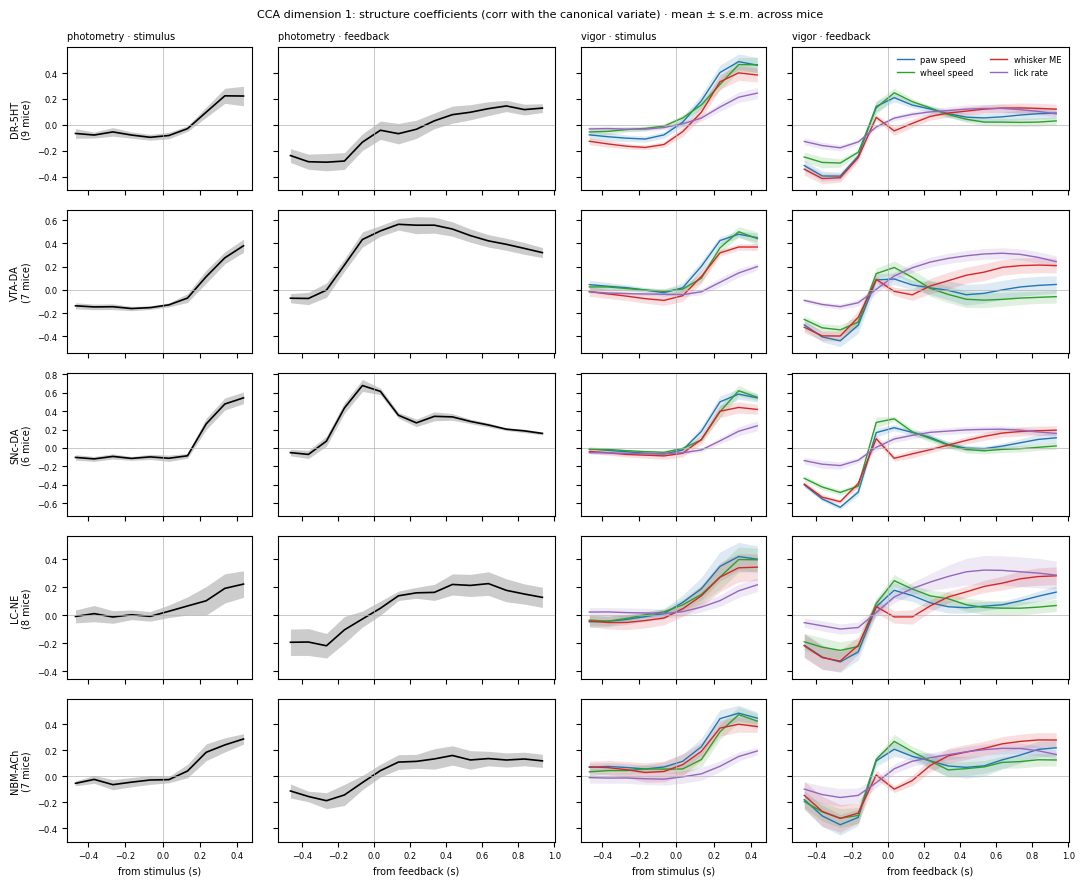

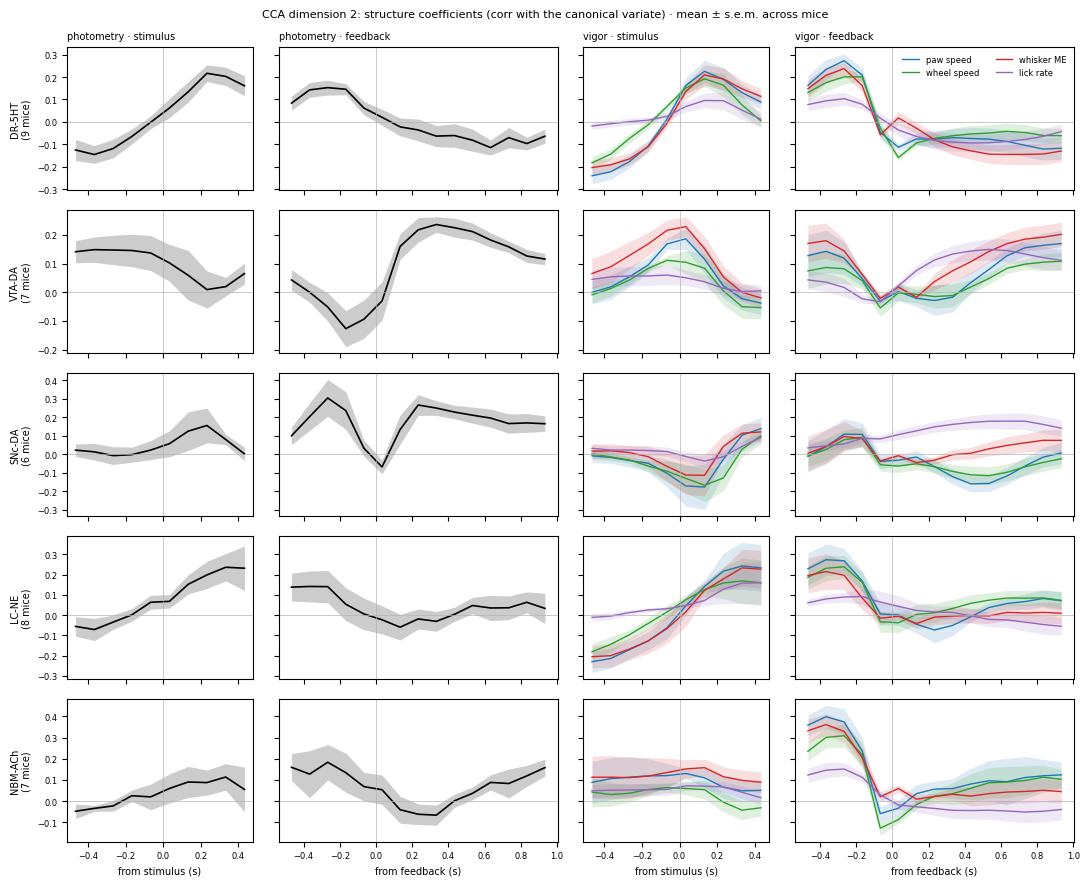

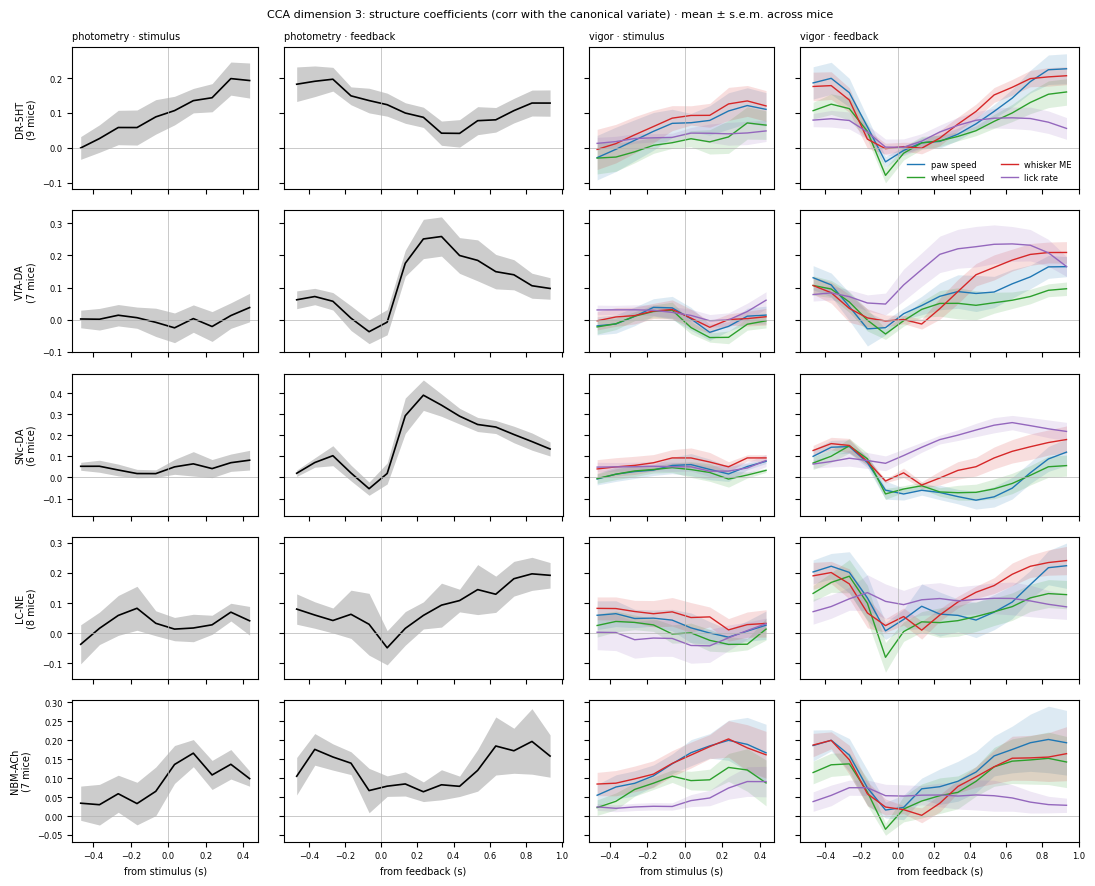

In [3]:
def align(L, n_iter=10):
    # flip each row's sign to agree with the mean of all rows
    L = L.copy()
    for _ in range(n_iter):
        s = np.sign(L @ L.mean(0)); s[s == 0] = 1
        L *= s[:, None]
    return L

def loadings(g, dim, kind='cca'):
    # per mouse: mean of session loadings after sign alignment; returns (y mice x 25, x mice x 100)
    if kind == 'cca':
        L = np.stack([np.r_[y[:, dim], x[:, dim]] for y, x in zip(g['cca_y_load'], g['cca_x_load'])])
    else:
        L = np.stack([np.r_[a[dim], w[:, dim] / (np.abs(w[:, dim]).max() + 1e-12)] for a, w in zip(g['rrr_y_axes'], g['rrr_x_weights'])])
    L = pd.DataFrame(align(L)).groupby(g['subject'].to_numpy()).mean().to_numpy()
    return L[:, :len(YLAB)], L[:, len(YLAB):]

def shape_figure(dim, kind='cca'):
    yw = np.array([l[0] for l in YLAB]); yt = np.array([l[2] for l in YLAB])
    xw = np.array([l[0] for l in XLAB]); xs = np.array([l[1] for l in XLAB]); xt = np.array([l[2] for l in XLAB])
    fig, axes = plt.subplots(len(NM_ORDER), 4, figsize=(11, 1.8 * len(NM_ORDER)), sharex='col', sharey='row' if kind == 'cca' else False,
                             gridspec_kw={'width_ratios': [2, 3, 2, 3]})
    for i, nm in enumerate(NM_ORDER):
        Ly, Lx = loadings(SH[SH['target_NM'] == nm], dim, kind)
        for k, w in enumerate(ns.WINDOWS):
            ax = axes[i, k]
            m = yw == w
            mu, se = Ly[:, m].mean(0), Ly[:, m].std(0) / np.sqrt(len(Ly) - 1)
            ax.plot(yt[m], mu, color='k', lw=1.2); ax.fill_between(yt[m], mu - se, mu + se, color='k', alpha=0.2, lw=0)
            ax = axes[i, 2 + k]
            for v, c in zip(ns.VIGOR, ['C0', 'C2', 'C3', 'C4']):
                m = (xw == w) & (xs == v)
                mu, se = Lx[:, m].mean(0), Lx[:, m].std(0) / np.sqrt(len(Lx) - 1)
                ax.plot(xt[m], mu, color=c, lw=1, label=v); ax.fill_between(xt[m], mu - se, mu + se, color=c, alpha=0.15, lw=0)
            for ax in axes[i, [k, 2 + k]]:
                ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5); ax.tick_params(labelsize=6)
        axes[i, 0].set_ylabel(f'{nm}\n({len(Ly)} mice)', fontsize=7)
    titles = ['photometry · stimulus', 'photometry · feedback', 'vigor · stimulus', 'vigor · feedback']
    for k, t in enumerate(titles):
        axes[0, k].set_title(t, fontsize=7, loc='left')
        axes[-1, k].set_xlabel(['from stimulus (s)', 'from feedback (s)'][k % 2], fontsize=7)
    axes[0, 3].legend(fontsize=6, frameon=False, ncol=2)
    what = (f'CCA dimension {dim + 1}: structure coefficients (corr with the canonical variate)' if kind == 'cca' else
            f'RRR axis {dim + 1}: photometry pattern (left) and the vigor weights that predict it (right, scaled to max 1)')
    fig.suptitle(f'{what} · mean ± s.e.m. across mice', fontsize=8)
    plt.tight_layout(); plt.show()

for d in range(3):
    shape_figure(d)

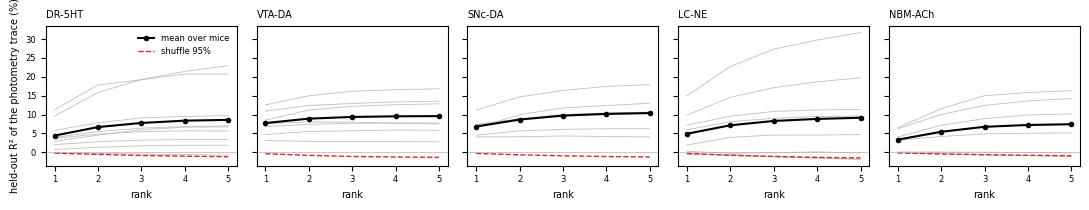

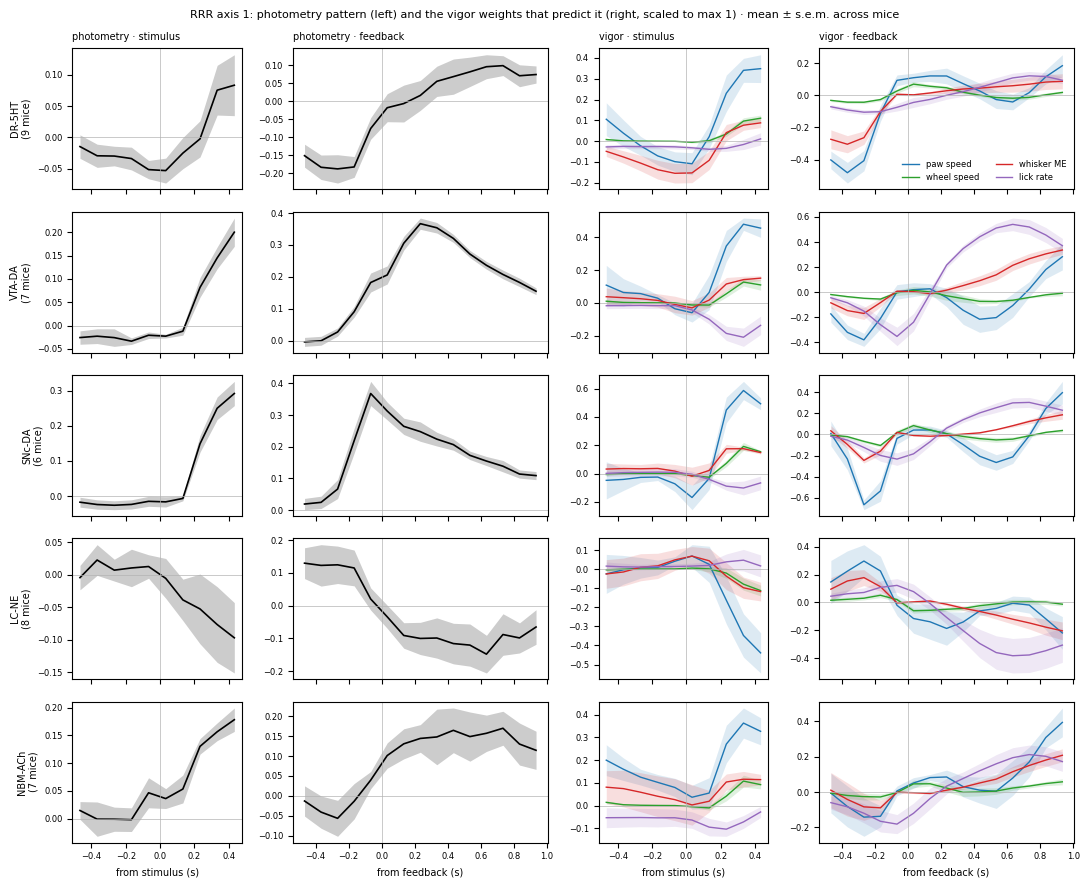

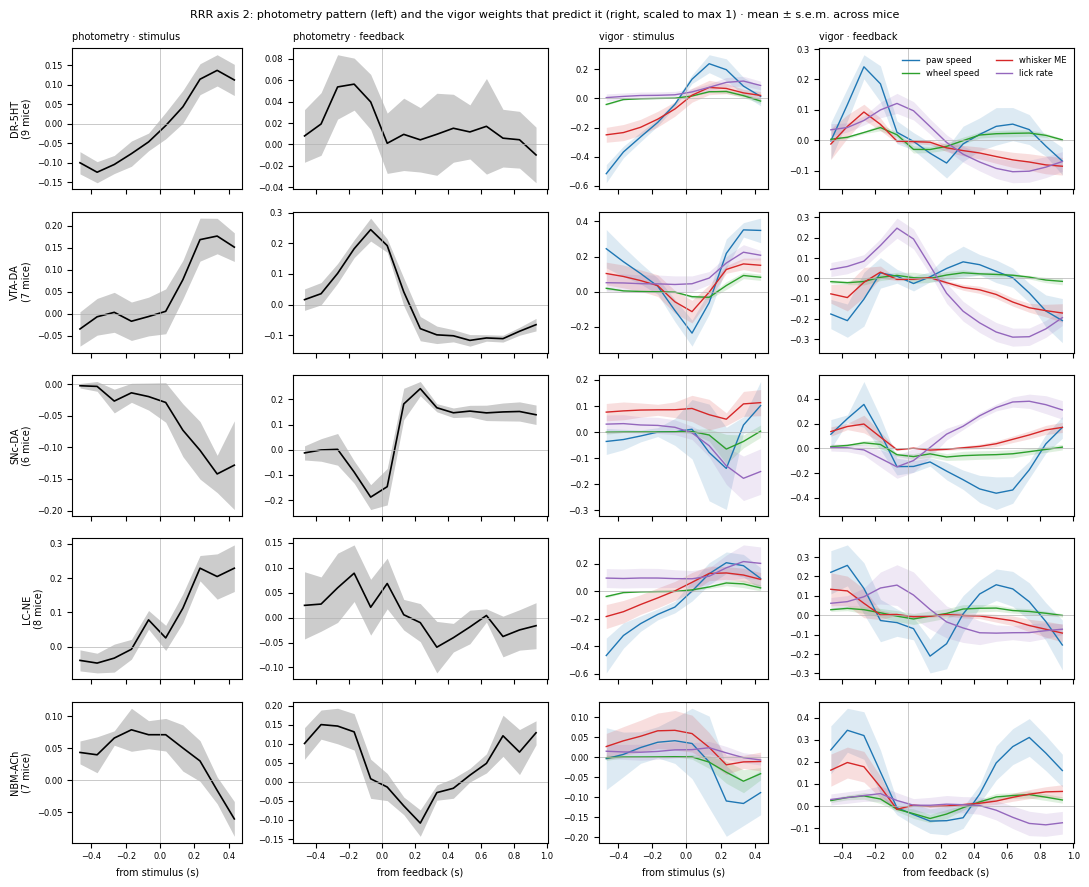

In [4]:
fig, axes = plt.subplots(1, len(NM_ORDER), figsize=(11, 2.2), sharey=True)
for ax, nm in zip(axes, NM_ORDER):
    g = SH[SH['target_NM'] == nm]
    r2, r2n = by_mouse(g, 'rrr_r2') * 100, by_mouse(g, 'rrr_r2_null', null95) * 100
    ranks = np.arange(1, r2.shape[1] + 1)
    for y in r2:
        ax.plot(ranks, y, color='0.75', lw=0.6)
    ax.plot(ranks, r2.mean(0), color='k', lw=1.5, marker='o', ms=3, label='mean over mice')
    ax.plot(ranks, r2n.mean(0), color='C3', lw=1, ls='--', label='shuffle 95%')
    ax.axhline(0, color='0.7', lw=0.5); ax.set_xticks(ranks); ax.tick_params(labelsize=6)
    ax.set_title(nm, fontsize=7, loc='left'); ax.set_xlabel('rank', fontsize=7)
axes[0].set_ylabel('held-out R² of the photometry trace (%)', fontsize=7); axes[0].legend(fontsize=6, frameon=False)
plt.tight_layout(); plt.show()

for d in range(2):
    shape_figure(d, kind='rrr')